In [1]:
import qiskit
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.result import Result
from qiskit.visualization import plot_histogram
from qiskit.quantum_info import Statevector
from qiskit.quantum_info.operators import Operator
from qiskit.providers.options import Options

from qiskit_aer.primitives import SamplerV2
from qiskit_aer.backends import AerSimulator
from qiskit_aer.jobs import AerJob


from matplotlib.pyplot import figure, bar
from matplotlib.axes import Axes
from matplotlib.figure import Figure
from matplotlib.font_manager import FontProperties


from IPython.display import display_latex
from numpy import sqrt
from numpy.random import randint

import typing


RUN_COUNT = 3000
"unitary" in AerSimulator().configuration().basis_gates

True

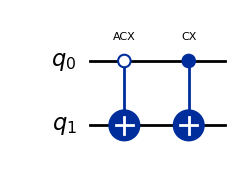

In [2]:
# Alice's random definition of function
(f_0, f_1) = randint(2, size=2)
display_latex(f"Alice defined $f(0)={f_0}$ and $f(1)={f_1}$", raw=True)
# Alice's construction of the Function Oracle Gate
q_U_f = QuantumRegister(2, name="q")
U_f = QuantumCircuit(q_U_f)

# Classically controlled CNOTs for function evaluation
if f_0 == 1:
    U_f.cx(control_qubit=q_U_f[0], target_qubit=q_U_f[1], label="ACX", ctrl_state=0)
if f_1 == 1:
    U_f.cx(control_qubit=q_U_f[0], target_qubit=q_U_f[1], label="CX", ctrl_state=1)

# Displaying Gate Definition
U_f_fig: Figure = U_f.draw(output="mpl") # type: ignore
U_f_op = Operator.from_circuit(circuit=U_f)
U_f_op_latex = f"$U_f = {str(U_f_op.draw("latex_source")).replace("\n", "")}$"

display_latex(f"Alice constructed function oracle, $U_f$", raw=True)
display(U_f_fig)
display_latex(U_f_op_latex, raw=True)

pass

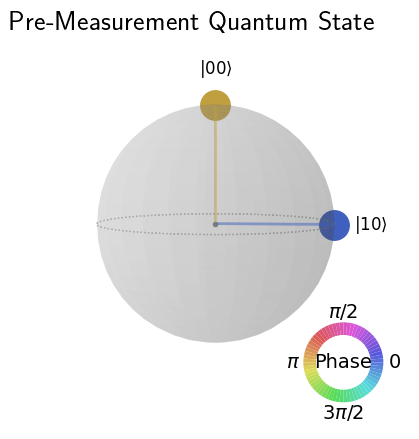

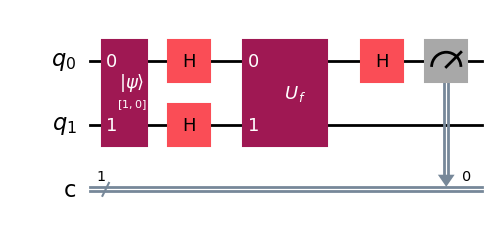

In [3]:
# Deutsch's Algorithm
q = QuantumRegister(2, name="q")
c = ClassicalRegister(1, name="c")

qc = QuantumCircuit(q, c)
# For Deutsch's algorithm, Bob initializes state (q1, q0)=(1, 0)
qc.initialize("10", q,)
# in order to prepare state (q1, q0)=(-, +)
qc.h(q)


# Bob recieves U_f as a black box, to operate on his registers and evaluate Alice's function for the state q1
qc.unitary(U_f_op, q, label="    $U_f$    ")

qc.h(q[0])

# state before measurement
qc_qsphere:Figure = Statevector(qc).draw('qsphere')# type: ignore
# figure adjustment
qc_qsphere.tight_layout(pad=0)
qc_qsphere.text(x=0,y=1,s="\\par{}Pre-Measurement Quantum State", fontdict={"size":20,"usetex":True})
qc_qsphere.set_size_inches(4,4)
# Bob measures 
qc.measure(qubit=q[0], cbit=c)
display(qc_qsphere)
display(qc.draw("mpl"))
pass

In [4]:
# Simulate with Qiskit Aer
backend: AerSimulator = AerSimulator()

# Alice can transpile the algorithm's circuit and run it for Bob.
qc_trans: QuantumCircuit = transpile(qc, backend)


# Queue a job for the backend: running the transpiled circuit 128 times
job: AerJob = backend.run(qc_trans, shots=RUN_COUNT)
# job: AerJob = backend.run((lambda qc: qc if (qc.h(0), qc.measure_all()) else qc)(QuantumCircuit(1)), shots=RUN_COUNT)
# Recieve results from the job
res: Result = job.result()
# Read measurements from Result object
counts: dict[str, int] = res.get_counts() # pyright: ignore[reportAssignmentType]
# add "key":0 counts
if not '0' in counts:
	counts['0']=0
if not '1' in counts:
	counts['1']=0



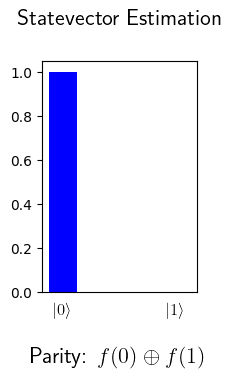

In [5]:
# Create statevector graph
statevector_bar_chart : Figure = figure(figsize=(2, 3))
# Set Title
statevector_bar_chart.text(x=0,y=1,s="Statevector Estimation", usetex=True, fontdict={"size":16, "weight":"bold"})


# Plot statevectors 
bar(x=0, height=sqrt(counts["0"]/RUN_COUNT), width=.25, bottom=0, data=counts["0"], color="blue")
bar(x=1, height=(counts["1"]/RUN_COUNT)**.5, width=.25, bottom=0, data=counts["1"], color="blue")

# Edit Axes
statevector_bar_chart_axes = statevector_bar_chart.axes[0]

# x axis
statevector_bar_chart_axes.set_xlabel(xlabel="\\par\nParity: $f(0)\\oplus f(1)$", usetex=True, fontdict={"size":16, "weight":"bold", "math_fontfamily":"cm"})
statevector_bar_chart_axes.tick_params(axis="x", which="both", width=0)

statevector_bar_chart_axes.set_xticks([0, 1], [r"\[\vert 0 \rangle\]", r"\[\vert 1 \rangle\]"], usetex=True, fontsize=12)

# y axis


parity_Bob = int(list(counts.keys())[0])
display_latex(rf"Bob has figured out that $f(0) \oplus f(1) = {parity_Bob}$, so the parity is {"odd" if parity_Bob else "even"}", raw=True)

parity_Alice = (f_0 + f_1) % 2
display_latex(rf"Alice confirms that since $f(0)={f_0}$ and $f(1)={f_1}$, $f(0) \oplus f(1) = {f_0} \oplus {f_1} = {(f_0 + f_1) % 2}$", raw=True)
pass